YOU MUST STILL FILL IN THfE FOLLOWING VARIABLES:
VARIABLES START


varyingVariable,
hasBottail,
obtaining_motor_csv,
numberSims,
processes,
latitude,
longitude,
elevation,
atmosphere_type,
env_file,
fahrenheit_temp,
pressure,
wind_u,
wind_v,
date,
generatedFilesLocation,
dryMotorMass,
propellant_mass,
grainInnerRadius,
grainOuterRadius,
grainHeight,
the_nozzle_radius,
the_throat_radius,
the_nozzle_position,
grain_center_of_mass_position,
center_of_dry_mass_within_motor,
motor_thrust_file,
burn_time,
numGrains,
grainSeparation,
the_motor_position,
the_center_of_mass_without_motor,
rocket_center_of_dry_mass_position,
power_off_file,
power_on_file,
inclination,
heading,
rail_length,
using-airbrakes,
doing_monte_carlo,


VARIABLES END


Impulse is: 9680.79964519286
TOTAL SIMS IS: 30


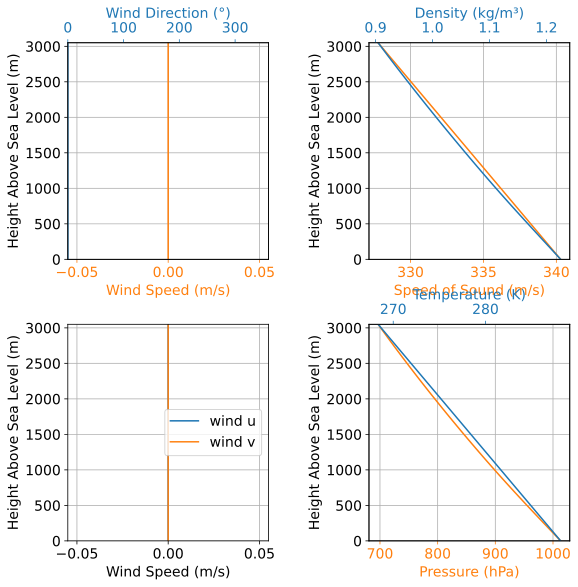

CURRENT HOUR IS 8, CURRENT DAY IS: 12


'Completed 30 iterations successfully. Total CPU time: 0.09375 s. Total wall time: 12.662537574768066 s'

Number of simulations:  30
Out Of Rail Stability Margin -         Mean Value: 3.141 
Out Of Rail Stability Margin - Standard Deviation: 0.000 m
PROBABILITY THE Out Of Rail Stability Margin IS IN BETWEEN 1.5 AND 4 IS: 100.0%
There is a 90% chance that the mean of the Out Of Rail Stability Margin falls within THIS RANGE: 3.1412276344693644, 3.1412276344693653



Apogee Altitude -         Mean Value: 5792.355 
Apogee Altitude - Standard Deviation: 0.000 m
PROBABILITY THE Apogee Altitude IS IN BETWEEN 3017.52 AND 3078.48 IS: 0.0%
There is a 90% chance that the mean of the Apogee Altitude falls within THIS RANGE: 5792.35458165443, 5792.354581654432

We have the hypothesis that our mean is greater than or equal to 3048. With our critical percent, our critical value is -1.6448536269514729. Then, our test statistic is 5509084356528307.0
Since our test statistic is less extreme than our critical value, we can NOT reject the null hypothesis that the mean is 3048.




----------------------------

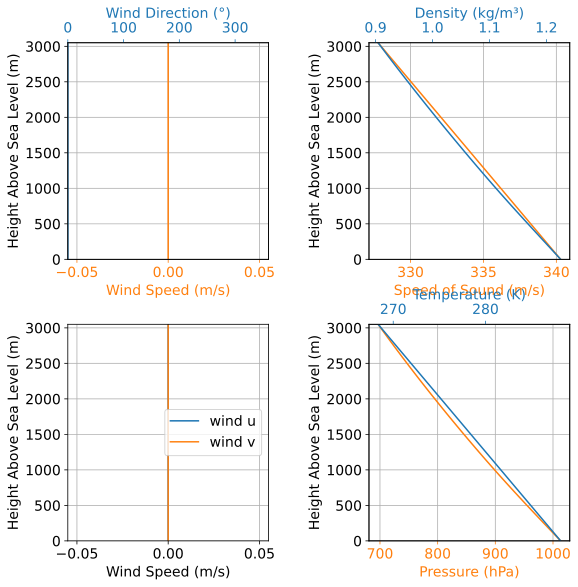

CURRENT HOUR IS 9, CURRENT DAY IS: 12


'Starting'

In [ ]:
from datetime import datetime
from time import process_time, time
import pandas as pd
from rocketpy import Environment, SolidMotor, Rocket, Flight
import concurrent.futures
from Helpers.ConcurrentFunctions import RunFlightWithMonteCarlo
from rocketpy.motors import motor
from IPython.display import display
from scipy.stats import norm
from rocketpy.mathutils.function import Function
from rocketpy.environment import environment

#Calculate and plot landing elipses
# Import libraries
from imageio import imread
from matplotlib.patches import Ellipse

from Helpers import FlightParams
from Helpers.Wind import MakeWind

%config InlineBackend.figure_formats = ['svg']
import matplotlib as mpl
import matplotlib.pyplot as plt


%matplotlib inline
mpl.rcParams["figure.figsize"] = [8, 5]
mpl.rcParams["figure.dpi"] = 120
mpl.rcParams["font.size"] = 14
mpl.rcParams["legend.fontsize"] = 14
mpl.rcParams["figure.titlesize"] = 14


import logging
import numpy as np

launchDate = [2025, 6, 12, 8]

#sets up the ability to log inputs.
def setup_logging():
    class MyHandler(logging.FileHandler):
        def emit(self, record):
            super().emit(record)  # Call the superclass's emit method
            self.flush()  # Flush after each log message

    # Use your custom handler
    logger = logging.getLogger()
    logger.setLevel(logging.INFO)
    handler = MyHandler('app.log', 'a')
    formatter = logging.Formatter('%(asctime)s - %(levelname)s - %(message)s')
    handler.setFormatter(formatter)
    logger.addHandler(handler)

resultsFile = open(FlightParams.Parameters["generatedFilesLocation"] + "results.txt", "w")

# envParams["file"] = row[0].value

print("TOTAL SIMS IS: " + str(FlightParams.Parameters["numberSims"]))
resultsFile.write("TOTAL SIMS IS: " + str(FlightParams.Parameters["numberSims"]) + "\n\n\n")


for day in [12]:
    # varyingParamVals = [9,]
    # apogeeAtIteration = [0,]
    varyingParamVals = []
    apogeeAtIteration = []
    currentVal = -1
    endVal = -1
    incrementAmount = -1
    if(FlightParams.Parameters["varyingVariable"] == "airbrake"):   
        currentVal = 1
        endVal = 21
        incrementAmount = 1
    elif (FlightParams.Parameters["varyingVariable"] == "finposition"):
        currentVal = 2.55
        endVal = 2.62
        incrementAmount = 0.005
    elif (FlightParams.Parameters["varyingVariable"] == "weatherHour"):
        currentVal = launchDate[3]
        endVal = 18
        incrementAmount = 1
    
    #range only accepts integer values, so for now we make them integers and divide them later
    while(True):
        theLaunchDate = [launchDate[0], launchDate[1], launchDate[2], currentVal]
        
        if(FlightParams.Parameters["varyingVariable"] == "airbrake"):
            print("THIS IS WHERE WE DEPLOY AIRBRAKE " + str(currentVal) + " SECONDS AFTER BURNOUT")
            resultsFile.write("THIS IS WHERE WE DEPLOY AIRBRAKE " + str(currentVal) + " SECONDS AFTER BURNOUT\n")
            FlightParams.Parameters["monte_carlo_parameters"]["time_to_deploy_airbrake_after_burnout"] = (currentVal, 0)
            varyingParamVals.append(currentVal)
        elif(FlightParams.Parameters["varyingVariable"] == "finposition"):
            print("CURRENT FIN POSITION IS " + str(currentVal))
            resultsFile.write("CURRENT FIN POSITION IS " + str(currentVal) + "\n")
            FlightParams.Parameters["monte_carlo_parameters"]["fin_position"] = (currentVal, 0)
            varyingParamVals.append(currentVal)
        elif(FlightParams.Parameters["varyingVariable"] == "weatherHour"):
            env = Environment(
                date=theLaunchDate,
                latitude=FlightParams.Parameters["latitude"],
                longitude=FlightParams.Parameters["longitude"],
                max_expected_height=3050
            )
            env.set_atmospheric_model(type=FlightParams.Parameters["atmosphere_type"], file=FlightParams.Parameters["env_file"])
            env.plots.atmospheric_model()
            print("CURRENT HOUR IS " + str(currentVal) + ", CURRENT DAY IS: " + str(day))
            resultsFile.write("CURRENT HOUR IS " + str(currentVal) + ", CURRENT DAY IS: " + str(day) + "\n")
            varyingParamVals.append(currentVal)

        setup_logging()
        # env.all_info()
        # Create data files for inputs, outputs and error logging
        filename = "MonteCarlo" + str(currentVal)
        MonteCarloErrorFile = open("../Output/" + str(filename) + "_Errors.txt", "w")
        MonteCarloInputFile = open("../Output/" + str(filename) + "_Input.txt", "w")
        MonteCarloOutputFile = open("../Output/" + str(filename) + "_Output.txt", "w")

        initial_wall_time = time()
        initial_cpu_time = process_time()
        # Iterate over flight settings
        out = display("Starting", display_id=True)
        number_of_simulations = FlightParams.Parameters["numberSims"]
        totalProcesses = FlightParams.Parameters["processes"]
        simsPerProcess = number_of_simulations / totalProcesses

        # runFlightWithMonteCarlo(simsPerProcess, FlightParams.envParams, analysis_parameters, initial_cpu_time, False, theLaunchDate)
        
        # start multiprocessing
        if __name__ == "__main__":
            with concurrent.futures.ProcessPoolExecutor(max_workers=totalProcesses) as executor:
                results = [executor.submit(RunFlightWithMonteCarlo, simsPerProcess, initial_cpu_time, False, theLaunchDate) for _ in range(totalProcesses)] 
                for result in concurrent.futures.as_completed(results):
                    MonteCarloInputFile.write(result.result()[0] + "\n")
                    MonteCarloOutputFile.write(result.result()[1] + "\n")
                    MonteCarloErrorFile.write(result.result()[2] + "\n")

        ## Print and save total time
        final_string = f"Completed {number_of_simulations} iterations successfully. Total CPU time: {process_time() - initial_cpu_time} s. Total wall time: {time() - initial_wall_time} s"
        resultsFile.write(f"Completed {number_of_simulations} iterations successfully. Total CPU time: {process_time() - initial_cpu_time} s. Total wall time: {time() - initial_wall_time} s\n")
        out.update(final_string)
        MonteCarloInputFile.write(final_string + "\n")
        MonteCarloOutputFile.write(final_string + "\n")
        MonteCarloErrorFile.write(final_string + "\n")

        ## Close files
        MonteCarloInputFile.close()
        MonteCarloOutputFile.close()
        MonteCarloErrorFile.close()

        # Initialize variable to store all results
        dispersion_general_results = []

        dispersion_results = {
            "out_of_rail_time": [],
            "out_of_rail_velocity": [],
            "apogee_time": [],
            "apogee_altitude": [],
            "apogee_x": [],
            "apogee_y": [],
            "impact_x": [],
            "impact_y": [],
            "initial_static_margin": [],
            "out_of_rail_static_margin": [],
            "out_of_rail_stability_margin": [],
            "max_velocity": [],
            "execution_time": [],
        }

        # Get all dispersion results
        # Get file
        dispersion_output_file = open("../Output/" + str(filename) + "_Output.txt", "r+")

        # Read each line of the file and convert to dict
        for line in dispersion_output_file:
            # Skip comments lines
            if line[0] != "{":
                continue
            # Eval results and store them
            flight_result = eval(line)
            dispersion_general_results.append(flight_result)
            for parameter_key, parameter_value in flight_result.items():
                dispersion_results[parameter_key].append(parameter_value)

        # Close data file
        dispersion_output_file.close()

        # Print number of flights simulated
        N = len(dispersion_general_results)
        print("Number of simulations: ", N)
        resultsFile.write("Number of simulations: " + str(N) + "\n")

        # Retrieve dispersion data por apogee and impact XY position
        apogee_x = np.array(dispersion_results["apogee_x"])
        apogee_y = np.array(dispersion_results["apogee_y"])

        FlightParams.createDistributionPlot(resultsFile, dispersion_results["out_of_rail_stability_margin"], "Out Of Rail Stability Margin", lowerProbBound = 1.5, upperProbBound = 4, maxDecimals = 4, percentConfidence = 90, hypothesis = None, unit = "none", makeGraph = False, filename = "Rail" + str(currentVal))
        print("\n\n")
        resultsFile.write("\n\n")
        FlightParams.createDistributionPlot(resultsFile, dispersion_results["apogee_altitude"], "Apogee Altitude", lowerProbBound = 9900 * 0.3048, upperProbBound = 10100 * 0.3048, maxDecimals = 0, percentConfidence = 90, hypothesis = 3048, unit = "meter", makeGraph = False, filename = "Apogee" + str(currentVal))
        print("\n\n\n----------------------------------------------------------------------------------------------------\n\n\n")
        resultsFile.write("\n\n\n----------------------------------------------------------------------------------------------------\n\n\n")
        apogeeAtIteration.append(np.mean(dispersion_results["apogee_altitude"]))

        #img = imread("background.jpeg")

        # # Retrieve dispersion data por apogee and impact XY position
        # impact_x = np.array(dispersion_results["impact_x"])
        # impact_y = np.array(dispersion_results["impact_y"])

        # print(f"Simulated Landing Position x = {np.mean(dispersion_results['impact_x'])}, y = {np.mean(dispersion_results['impact_y'])}")
        # resultsFile.write(f"Simulated Landing Position x = {np.mean(dispersion_results['impact_x'])}, y = {np.mean(dispersion_results['impact_y'])}\n")
        # # Define function to calculate eigen values
        # def eigsorted(cov):
        #     vals, vecs = np.linalg.eigh(cov)
        #     order = vals.argsort()[::-1]
        #     return vals[order], vecs[:, order]


        # # Create plot figure
        # plt.figure(num=None, figsize=(8, 6), dpi=150, facecolor="w", edgecolor="k")
        # ax = plt.subplot(111)

        # # Calculate error ellipses for impact
        # impactCov = np.cov(impact_x, impact_y)
        # impactVals, impactVecs = eigsorted(impactCov)
        # impactTheta = np.degrees(np.arctan2(*impactVecs[:, 0][::-1]))
        # impactW, impactH = 2 * np.sqrt(impactVals)

        # # Draw error ellipses for impact
        # impact_ellipses = []
        # for j in [1, 2, 3]:
        #     impactEll = Ellipse(
        #         xy=(np.mean(impact_x), np.mean(impact_y)),
        #         width=impactW * j,
        #         height=impactH * j,
        #         angle=impactTheta,
        #         color="black",
        #     )
        #     impactEll.set_facecolor((0, 0, 1, 0.2))
        #     impact_ellipses.append(impactEll)
        #     ax.add_artist(impactEll)

        # # Calculate error ellipses for apogee
        # apogeeCov = np.cov(apogee_x, apogee_y)
        # apogeeVals, apogeeVecs = eigsorted(apogeeCov)
        # apogeeTheta = np.degrees(np.arctan2(*apogeeVecs[:, 0][::-1]))
        # apogeeW, apogeeH = 2 * np.sqrt(apogeeVals)

        # # Draw error ellipses for apogee
        # for j in [1, 2, 3]:
        #     apogeeEll = Ellipse(
        #         xy=(np.mean(apogee_x), np.mean(apogee_y)),
        #         width=apogeeW * j,
        #         height=apogeeH * j,
        #         angle=apogeeTheta,
        #         color="black",
        #     )
        #     apogeeEll.set_facecolor((0, 1, 0, 0.2))
        #     ax.add_artist(apogeeEll)

        # # Draw launch point
        # plt.scatter(0, 0, s=30, marker="*", color="black", label="Launch Point")
        # # Draw apogee points
        # plt.scatter(
        #     apogee_x, apogee_y, s=5, marker="^", color="green", label="Simulated Apogee"
        # )
        # # Draw impact points
        # plt.scatter(
        #     impact_x, impact_y, s=5, marker="v", color="blue", label="Simulated Landing Point"
        # )

        # plt.legend()

        # # Add title and labels to plot
        # ax.set_title(
        #     "1$\sigma$, 2$\sigma$ and 3$\sigma$ Dispersion Ellipses: Apogee and Lading Points"
        # )
        # ax.set_ylabel("North (m)")
        # ax.set_xlabel("East (m)")

        # # Add background image to plot
        # # You can translate the basemap by changing dx and dy (in meters)
        # dx = 0
        # dy = 0
        # #plt.imshow(img, zorder=0, extent=[-1000 - dx, 1000 - dx, -1000 - dy, 1000 - dy])

        # plt.axhline(0, color="black", linewidth=0.5)
        # plt.axvline(0, color="black", linewidth=0.5)
        # plt.xlim(-5000, 5000)
        # plt.ylim(-5000, 5000)

        # Save plot and show result
        # plt.savefig("OutputFiles/" + str(filename) + ".pdf", bbox_inches="tight", pad_inches=0)
        # plt.savefig("OutputFiles/" + str(filename) + ".svg", bbox_inches="tight", pad_inches=0)
        # plt.show()
        print("\n\n\n----------------------------------------------------------------------------------------------------\n\n\n")
        resultsFile.write("\n\n\n----------------------------------------------------------------------------------------------------\n\n\n")

        currentVal += incrementAmount
        currentVal = round(currentVal, 5 )
        if(currentVal > endVal):
            break

    plt.scatter(varyingParamVals, apogeeAtIteration)
    if(FlightParams.varyingVariable == "airbrake"):
        plt.title("Apogees at Different Deployment Times")
        plt.xlabel("Airbrake Deployment Time (Seconds after Burnout)")
        plt.ylabel("Apogee for that Time")
    elif(FlightParams.varyingVariable == "finposition"):
        plt.title("Apogees at Different Fin Positions")
        plt.xlabel("Fin Position")
        plt.ylabel("Apogee for that Position")
    elif(FlightParams.varyingVariable == "weatherHour"):
        plt.title(f"Apogees for Different Hours On Day {day}")
        plt.xlabel("Hour (Military Time)")
        plt.ylabel("Apogee at that hour")
        plt.axhline(3048, color='k', linestyle='solid', linewidth=4)
        plt.text(9.75, 3048, f'Desired Apogee', va='bottom', ha='left', color='red')
        
    #creating the trendline with the given x and y values
    trendline = np.polyfit(varyingParamVals, apogeeAtIteration, 1)
    trendline = np.poly1d(trendline)
    # obtaining the y values from the trendline
    y_vals = trendline(varyingParamVals)

    # R^2 calculation
    residuals = apogeeAtIteration - y_vals
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((apogeeAtIteration - np.mean(apogeeAtIteration))**2)
    r_squared = 1 - (ss_res / ss_tot)

    #plotting the trendline
    # plt.plot(varyingParamVals, y_vals, "r", label="Trendline (R² = " + str(round(r_squared, 3)) + ")")
    # plt.legend()

    plt.savefig(FlightParams.Parameters["generatedFilesLocation"] + f"FinalSimTable{day}.png", bbox_inches="tight", pad_inches=0)
    plt.show()
resultsFile.close()